In [37]:
## PHASE 1 — Retail Data Understanding & Sales Analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df = pd.read_csv("/content/Walmartinspire.csv")
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [39]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [40]:
df.shape

(6435, 8)

In [41]:
df.columns

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment'],
      dtype='object')

In [42]:
df.dtypes

,0
Store,int64
Date,object
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [44]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [45]:
df.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True
)


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


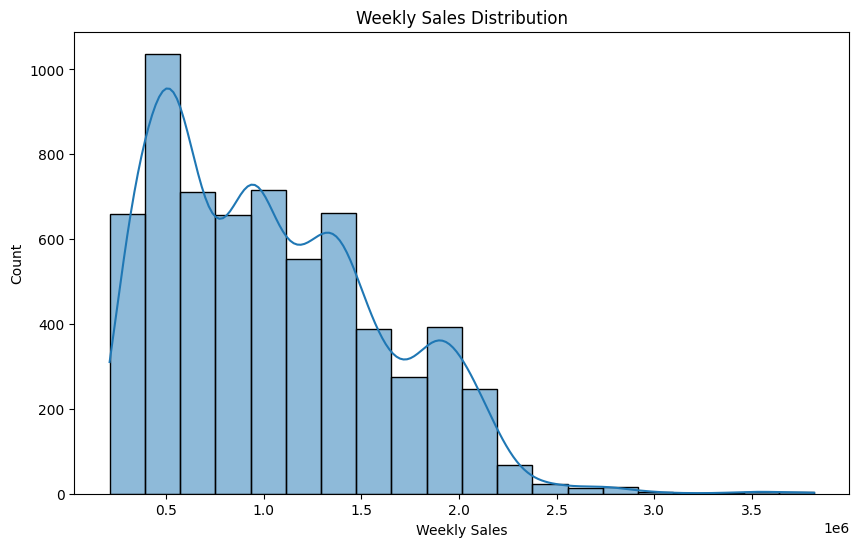

In [49]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Weekly_Sales"],
    bins=20,
    kde=True
)

plt.title("Weekly Sales Distribution")

plt.xlabel("Weekly Sales")

plt.show()

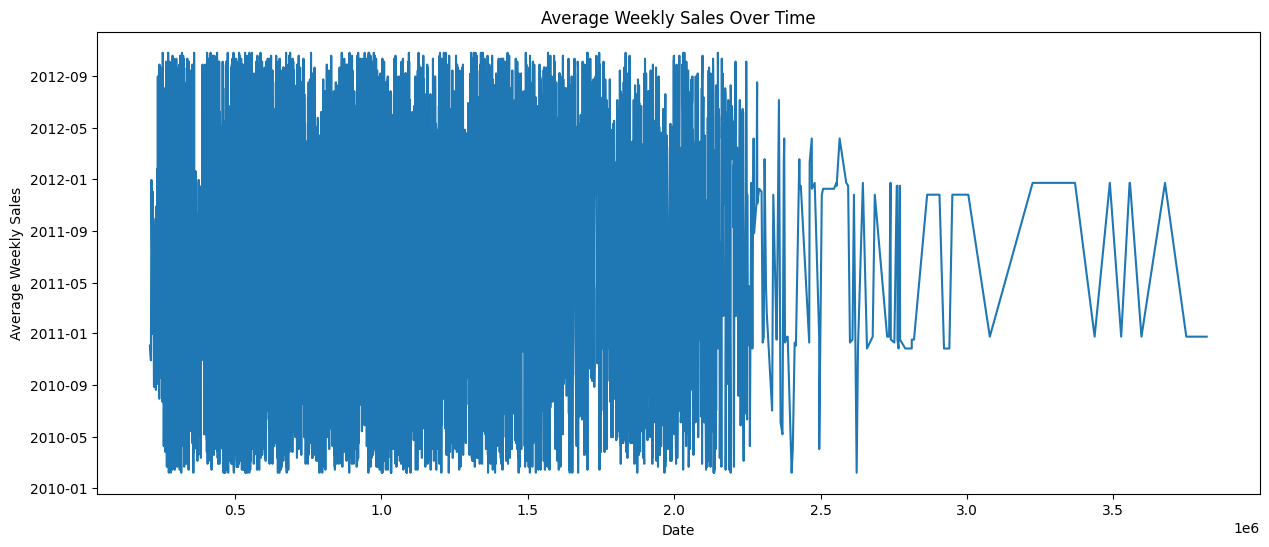

In [50]:
plt.figure(figsize=(15,6))

df.groupby("Weekly_Sales")["Date"].mean().plot()

plt.title("Average Weekly Sales Over Time")

plt.xlabel("Date")

plt.ylabel("Average Weekly Sales")

plt.show()

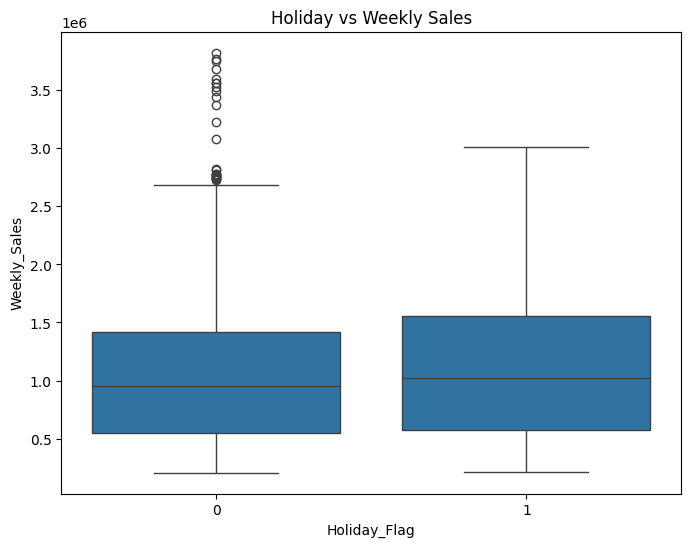

In [51]:
plt.figure(figsize=(8,6))

sns.boxplot(
    x="Holiday_Flag",
    y="Weekly_Sales",
    data=df
)

plt.title("Holiday vs Weekly Sales")

plt.show()

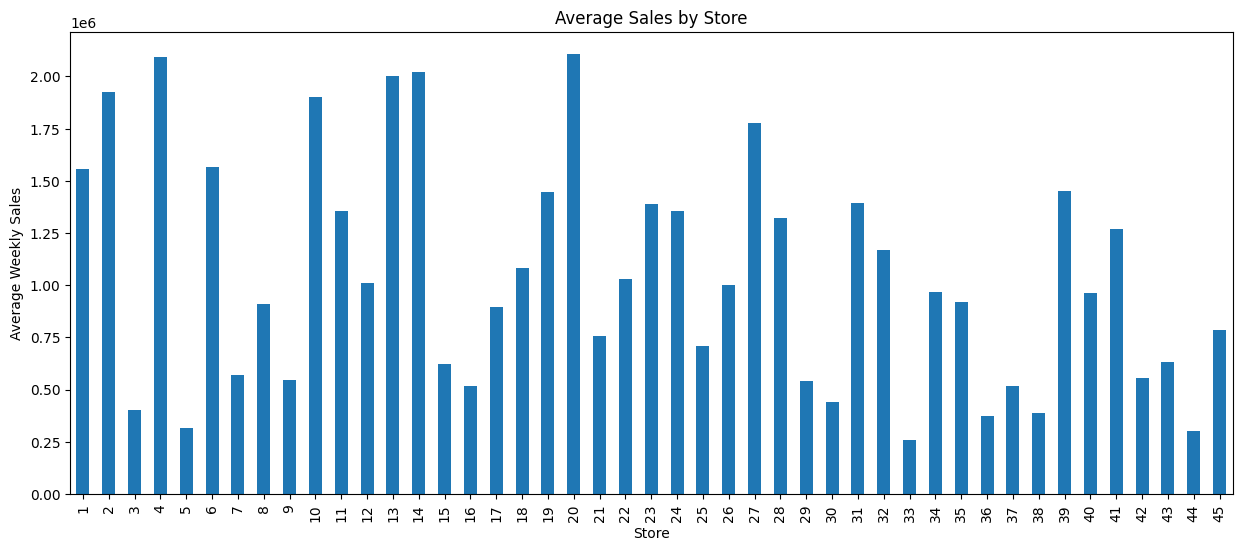

In [52]:
plt.figure(figsize=(15,6))

store_sales = df.groupby("Store")[
    "Weekly_Sales"
].mean()

store_sales.plot(kind="bar")

plt.title("Average Sales by Store")

plt.xlabel("Store")

plt.ylabel("Average Weekly Sales")

plt.show()

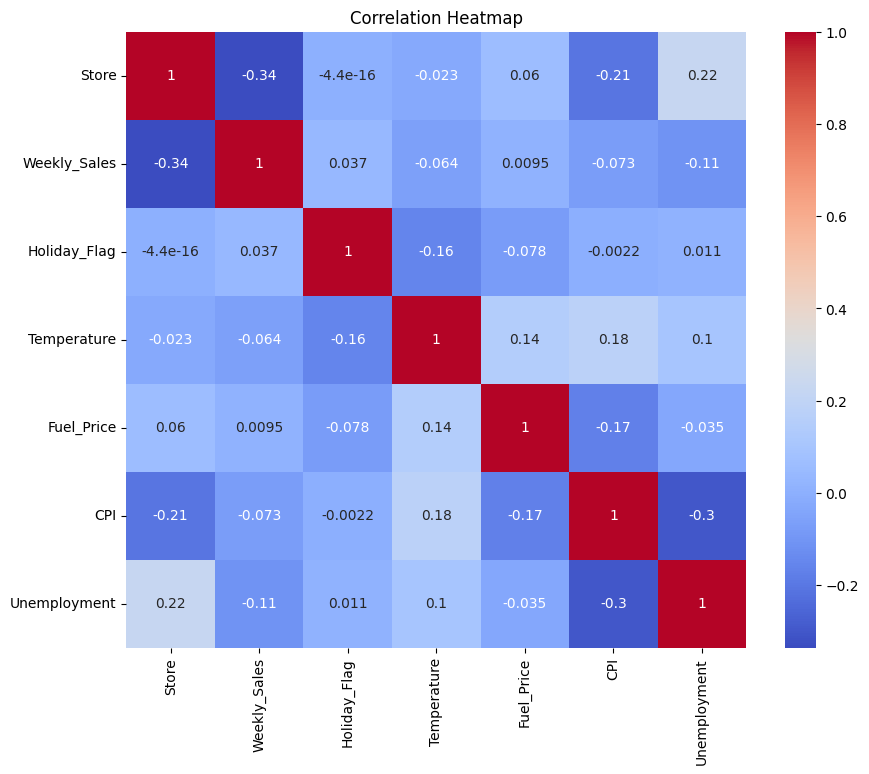

In [53]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

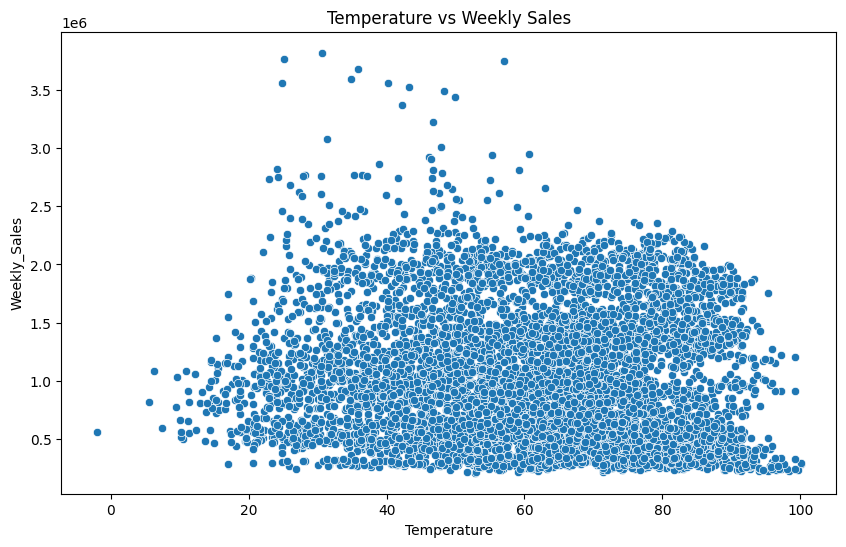

In [54]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Temperature",
    y="Weekly_Sales",
    data=df
)

plt.title("Temperature vs Weekly Sales")

plt.show()

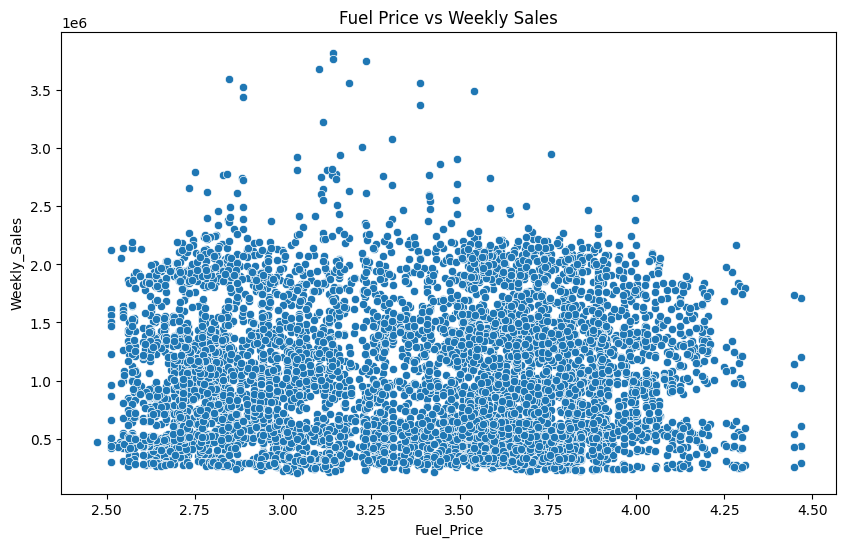

In [55]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Fuel_Price",
    y="Weekly_Sales",
    data=df
)

plt.title("Fuel Price vs Weekly Sales")

plt.show()

In [56]:
## PHASE 2 — Forecasting Feature Engineering
df["Year"] = df["Date"].dt.year

In [57]:
df["Month"] = df["Date"].dt.month

In [58]:
df["Week"] = df["Date"].dt.isocalendar().week

In [59]:
df["Day"] = df["Date"].dt.day

In [60]:
df["Quarter"] = df["Date"].dt.quarter

In [61]:
df["Previous_Week_Sales"] = df.groupby(
    "Store"
)["Weekly_Sales"].shift(1)

In [62]:
df["Rolling_Mean_4"] = df.groupby(
    "Store"
)["Weekly_Sales"].transform(
    lambda x: x.shift(1).rolling(window=4).mean()
)

In [63]:
df.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0
Year,0
Month,0


In [64]:
df.fillna(method="bfill", inplace=True)

/tmp/ipykernel_565/1916524838.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method="bfill", inplace=True)


In [65]:
df.drop("Date", axis=1, inplace=True)

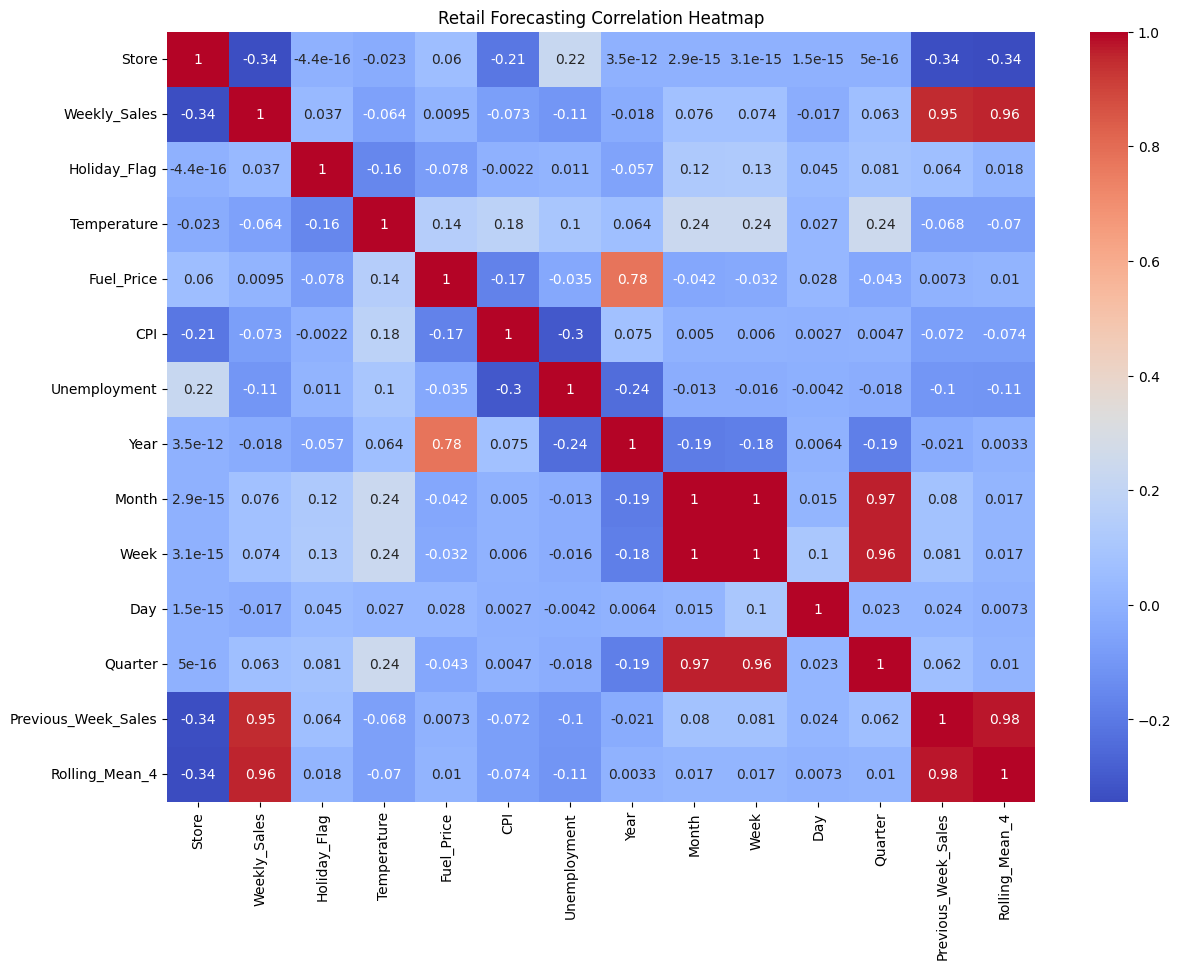

In [66]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Retail Forecasting Correlation Heatmap")

plt.show()

In [67]:
X = df.drop("Weekly_Sales", axis=1)

In [68]:
y = df["Weekly_Sales"]

In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

In [70]:
## PHASE 3 — Retail Demand Forecasting Model
from sklearn.ensemble import RandomForestRegressor

In [71]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

In [72]:
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, n_estimators=300, n_jobs=-1,
                      random_state=42)

In [73]:
y_pred = rf_model.predict(X_test)

In [74]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [75]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

In [76]:
print("Retail Demand Forecasting Results")

print("MAE :", mae)

print("RMSE:", rmse)

print("R2 Score:", r2)

Retail Demand Forecasting Results
MAE : 42930.859636897694
RMSE: 62715.19178732011
R2 Score: 0.9740139132426203


In [77]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(15))

                Feature  Importance
12       Rolling_Mean_4    0.724201
11  Previous_Week_Sales    0.220196
8                  Week    0.027811
9                   Day    0.014706
2           Temperature    0.002310
4                   CPI    0.002169
5          Unemployment    0.002048
3            Fuel_Price    0.001594
1          Holiday_Flag    0.001588
0                 Store    0.001508
7                 Month    0.001285
10              Quarter    0.000310
6                  Year    0.000274


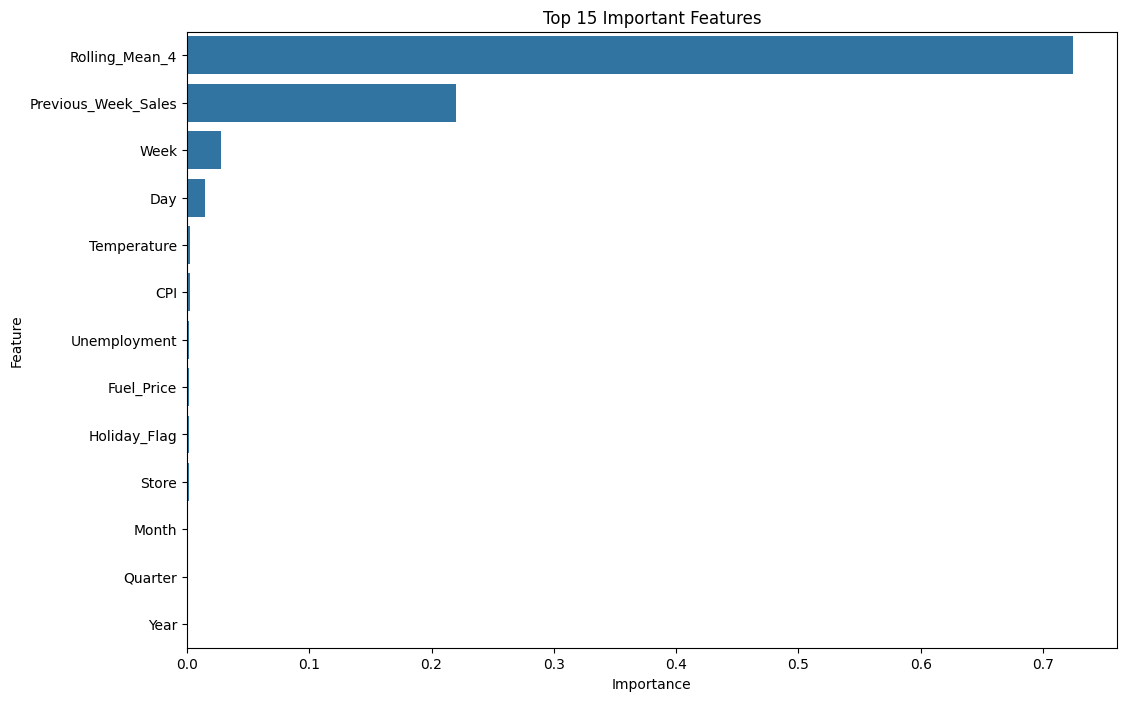

In [78]:
plt.figure(figsize=(12,8))

sns.barplot(
    x=importance["Importance"][:15],
    y=importance["Feature"][:15]
)

plt.title("Top 15 Important Features")

plt.show()

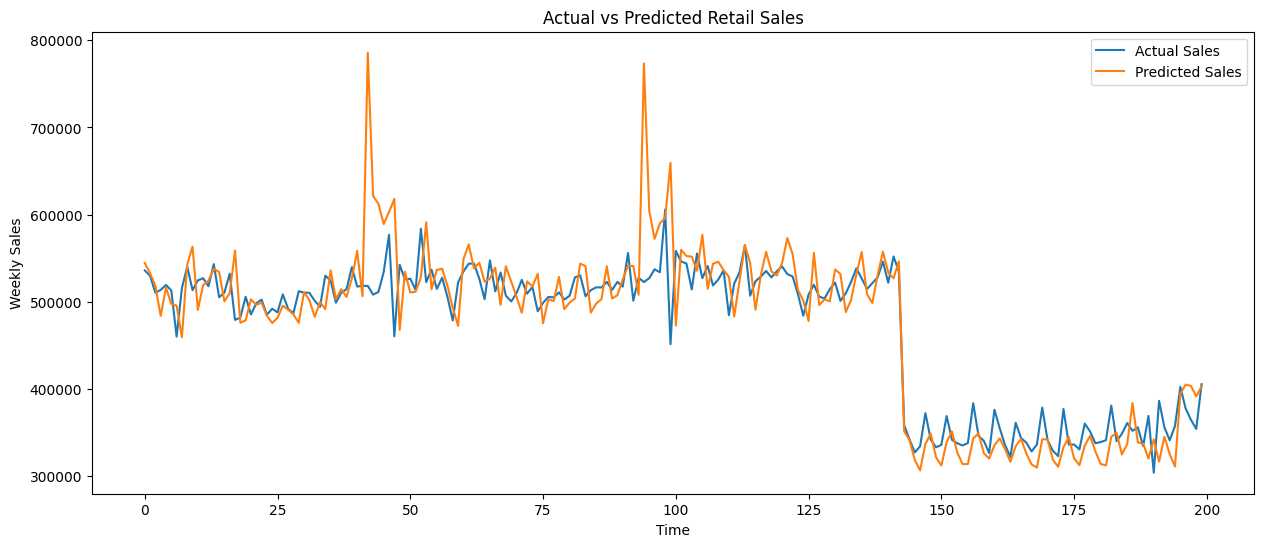

In [79]:
plt.figure(figsize=(15,6))

plt.plot(
    y_test.values[:200],
    label="Actual Sales"
)

plt.plot(
    y_pred[:200],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Retail Sales")

plt.xlabel("Time")

plt.ylabel("Weekly Sales")

plt.legend()

plt.show()

In [80]:
## PHASE 4 — Future Retail Demand Prediction System]
new_data = pd.DataFrame({
    "Store": [10],
    "Holiday_Flag": [1],
    "Temperature": [72],
    "Fuel_Price": [3.5],
    "CPI": [210],
    "Unemployment": [6.2],

    "Year": [2013],
    "Month": [11],
    "Week": [45],
    "Day": [7],
    "Quarter": [4],

    "Previous_Week_Sales": [1500000],

    "Rolling_Mean_4": [1450000]
})


In [81]:
new_data = new_data[X.columns]

In [82]:
future_prediction = rf_model.predict(new_data)

In [83]:
print("Predicted Future Weekly Sales:")

print(future_prediction[0])

Predicted Future Weekly Sales:
1564443.7412750004


In [84]:
!pip install -q gradio

In [85]:

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

def predict_sales(store, date, holiday, temperature,
                  fuel, cpi, unemployment,
                  previous_sales, rolling_mean):

    try:
        date = pd.to_datetime(date)

        new_data = pd.DataFrame({
            "Store": [int(store)],
            "Holiday_Flag": [int(holiday)],
            "Temperature": [temperature],
            "Fuel_Price": [fuel],
            "CPI": [cpi],
            "Unemployment": [unemployment],
            "Year": [date.year],
            "Month": [date.month],
            "Week": [date.isocalendar().week],
            "Day": [date.day],
            "Quarter": [date.quarter],
            "Previous_Week_Sales": [previous_sales],
            "Rolling_Mean_4": [rolling_mean]
        })

        new_data = new_data[X.columns]

        prediction = rf_model.predict(new_data)[0]

        result = f"""
        PREDICTION SUCCESSFUL

        Store: {int(store)}
        Forecast Date: {date.date()}

        Predicted Weekly Sales:
        ${prediction:,.2f}
        """

        return result

    except Exception as e:
        return f"Error: {str(e)}"


def show_charts():

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(y_test.values[:100], label="Actual Sales")
    ax.plot(y_pred[:100], label="Predicted Sales")

    ax.set_title("Actual vs Predicted Sales")
    ax.set_xlabel("Records")
    ax.set_ylabel("Weekly Sales")
    ax.legend()
    fig.tight_layout()

    return fig


def show_importance():

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.barh(
        importance["Feature"].head(10)[::-1],
        importance["Importance"].head(10)[::-1]
    )

    ax.set_title("Top 10 Important Features")
    fig.tight_layout()

    return fig


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Retail Demand Forecasting"
) as demo:

    gr.Markdown("""
    # RETAIL DEMAND FORECASTING SYSTEM

    ### AI Powered Weekly Sales Prediction

    Predict future retail sales using Random Forest Machine Learning.
    """)

    with gr.Tab("Dashboard"):

        gr.Markdown("## Sales Analytics")

        gr.Markdown(
            f"Total Records: {len(df)} | "
            f"Stores: {df['Store'].nunique()} | "
            f"Model: Random Forest Regressor"
        )

        gr.Plot(value=show_charts())

        gr.Plot(value=show_importance())

    with gr.Tab("Sales Prediction"):

        gr.Markdown("## Enter Store Details")

        with gr.Row():
            store = gr.Dropdown(
                choices=sorted(df["Store"].unique().tolist()),
                value=int(df["Store"].min()),
                label="Store Number"
            )

            date = gr.Textbox(
                value="2012-11-30",
                label="Forecast Date (YYYY-MM-DD)"
            )

        with gr.Row():
            holiday = gr.Radio(
                choices=[0, 1],
                value=0,
                label="Holiday Flag"
            )

            temperature = gr.Number(
                value=50,
                label="Temperature"
            )

        with gr.Row():
            fuel = gr.Number(
                value=3.5,
                label="Fuel Price"
            )

            cpi = gr.Number(
                value=180,
                label="CPI"
            )

            unemployment = gr.Number(
                value=7,
                label="Unemployment"
            )

        gr.Markdown("### Previous Sales Information")

        with gr.Row():
            previous_sales = gr.Number(
                value=1500000,
                label="Previous Week Sales"
            )

            rolling_mean = gr.Number(
                value=1450000,
                label="4 Week Rolling Mean"
            )

        predict_btn = gr.Button(
            "PREDICT WEEKLY SALES",
            variant="primary"
        )

        result = gr.Textbox(
            label="Prediction Result",
            lines=5
        )

        predict_btn.click(
            fn=predict_sales,
            inputs=[
                store, date, holiday, temperature,
                fuel, cpi, unemployment,
                previous_sales, rolling_mean
            ],
            outputs=result
        )

    with gr.Tab("About Project"):

        gr.Markdown("""
        ## Retail Demand Forecasting System

        **Algorithm:** Random Forest Regressor

        **Dataset:** Walmart Sales Dataset

        **Programming Language:** Python

        **Libraries:**
        - Pandas
        - NumPy
        - Matplotlib
        - Seaborn
        - Scikit-learn
        - Gradio

        **Objective:**

        Predict future weekly sales and help retail
        businesses manage inventory and demand.
        """)

demo.launch(share=True)


/tmp/ipykernel_565/3160689583.py:79: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d6c95baff215607286.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
